# Phase 2 - Baselines: bicubic vs original SEN2SR

Now that the data is ready (Phase 1), we measure the two baselines that everything later has to beat:
- **A. Bicubic interpolation** - the simplest way to make the image 4x bigger
- **B. Original pretrained SEN2SR** - no changes at all

We use the **validation** split only. The test split stays untouched until the final evaluation (Phase 5), so we can't accidentally tune anything on it.

Plan:
1. Load the validation pairs and the model
2. Choose the bicubic version
3. Define the metrics and test them on one image
4. Run both methods on all validation images
5. Compare: tables, how often SEN2SR wins, pictures

In [1]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
import mlstac
import rasterio
from skimage.metrics import structural_similarity

device = "mps" if torch.backends.mps.is_available() else "cpu"
print("device:", device)

device: mps


## 1. Load the validation pairs and the model

In [2]:
index = pd.read_csv("dataset_index.csv")
val = index[index["split"] == "val"].reset_index(drop=True)

print("all pairs:", len(index))
print("validation pairs:", len(val))
print("validation pairs marked low_fit:", val["low_fit"].sum())

all pairs: 2851
validation pairs: 433
validation pairs marked low_fit: 65


`load_pair` is copied from Phase 1 (LR and HR both in reflectance), `super_resolve` from Phase 0 (pad 121 → 128, run, crop to 484).

In [3]:
data_dir = "sen2naip/cross-sensor"
band_names = ["R", "G", "B", "NIR"]

def load_pair(row):
    with rasterio.open(os.path.join(data_dir, row["folder"], "lr.tif")) as f:
        lr = np.clip(f.read().astype(np.float32) / 10000, 0, None)
    with rasterio.open(os.path.join(data_dir, row["folder"], "hr.tif")) as f:
        hr = f.read().astype(np.float32)
    for b, band in enumerate(band_names):
        hr[b] = row["a_" + band] * hr[b] + row["b_" + band]
    hr = np.clip(hr, 0, None)
    return lr, hr

model = mlstac.load("model/SEN2SRLite_RGBN_x4").compiled_model(device=device)

def super_resolve(lr):
    # lr: numpy (4, H, W) -> numpy (4, 4H, 4W)
    x = torch.from_numpy(lr).unsqueeze(0)
    h, w = x.shape[2], x.shape[3]
    x = F.pad(x, (0, 128 - w, 0, 128 - h), mode="replicate")
    with torch.no_grad():
        out = model(x.to(device)).cpu()
    return out[0, :, :h * 4, :w * 4].numpy()

lr, hr = load_pair(val.iloc[0])
sr = super_resolve(lr)
print("lr:", lr.shape, "| hr:", hr.shape, "| sr:", sr.shape)

lr: (4, 121, 121) | hr: (4, 484, 484) | sr: (4, 484, 484)


## 2. Which bicubic?

PyTorch's `F.interpolate(mode="bicubic")` has an option `antialias`. SEN2SR's hard constraint uses `antialias=True` internally. Let's check if the two versions give different results on the first 50 validation images, and use the better one - the baseline should be as strong as possible, otherwise beating it means nothing.

In [4]:
def bicubic(lr, antialias):
    x = torch.from_numpy(lr).unsqueeze(0)
    up = F.interpolate(x, scale_factor=4, mode="bicubic", antialias=antialias)
    return up[0].clamp(min=0).numpy()

def psnr(pred, target):
    mse = np.mean((pred - target) ** 2)
    return 10 * np.log10(1.0 / mse)

psnr_aa, psnr_plain = [], []
for i in range(50):
    lr, hr = load_pair(val.iloc[i])
    psnr_aa.append(psnr(bicubic(lr, True), hr))
    psnr_plain.append(psnr(bicubic(lr, False), hr))

print("mean PSNR antialias=True :", round(np.mean(psnr_aa), 3))
print("mean PSNR antialias=False:", round(np.mean(psnr_plain), 3))
print("antialias=True better on", sum(a > b for a, b in zip(psnr_aa, psnr_plain)), "of 50 images")

mean PSNR antialias=True : 34.358
mean PSNR antialias=False: 34.362
antialias=True better on 20 of 50 images


In [5]:
use_antialias = np.mean(psnr_aa) > np.mean(psnr_plain)
print("bicubic baseline uses antialias =", use_antialias)

bicubic baseline uses antialias = False


## 3. Metrics

All images are reflectance. We use a **fixed data range of 1.0** for PSNR and SSIM (reflectance goes from 0 to ~1), so the numbers are comparable between images and methods.

| metric | what it measures | better |
|---|---|---|
| PSNR | pixel error (log scale) | higher |
| SSIM | similarity of local structure (edges, textures) | higher |
| MAE | average absolute error | lower |
| RMSE | error, punishes big mistakes more | lower |
| SAM | angle between the 4-band "colour" vectors of SR and HR, in degrees → is the *spectrum* right? | lower |
| LR consistency | shrink the output back to 10 m and compare with the LR input (PSNR) → does the output still agree with what the satellite saw? | higher |

**Border:** we cut 8 pixels from each side before computing metrics. The edge of the image is where the padding happened and where bicubic has no neighbours, so it is not a fair place to judge.

In [6]:
border = 8

def crop(img):
    return img[:, border:-border, border:-border]

def ssim(pred, target):
    return structural_similarity(target, pred, data_range=1.0, channel_axis=0)

def mae(pred, target):
    return np.mean(np.abs(pred - target))

def rmse(pred, target):
    return np.sqrt(np.mean((pred - target) ** 2))

def sam(pred, target):
    # angle between the 4-band vectors at every pixel, averaged, in degrees
    pred, target = pred.astype(np.float64), target.astype(np.float64)   # float64: arccos is sensitive to rounding near 1
    dot = np.sum(pred * target, axis=0)
    norms = np.linalg.norm(pred, axis=0) * np.linalg.norm(target, axis=0)
    valid = norms > 0          # the angle is undefined if a pixel is 0 in all bands
    cos = np.clip(dot[valid] / norms[valid], -1, 1)
    return np.degrees(np.arccos(cos)).mean()

def lr_consistency(pred, lr):
    # average every 4x4 block -> back to 10 m
    small = pred.reshape(4, pred.shape[1] // 4, 4, pred.shape[2] // 4, 4).mean(axis=(2, 4))
    return psnr(small, lr)

def all_metrics(pred, hr, lr):
    p, h = crop(pred), crop(hr)
    return {"psnr": psnr(p, h), "ssim": ssim(p, h), "mae": mae(p, h), "rmse": rmse(p, h),
            "sam": sam(p, h), "lr_consistency": lr_consistency(pred, lr)}

Sanity test on one image: comparing HR with itself should give perfect scores (PSNR infinite, SSIM 1, errors 0, SAM 0).

Why the `valid` mask in SAM: a few very dark HR pixels (shadows, water) become 0 in **all** bands after the reflectance conversion + clipping. The angle of a zero vector is undefined, so those pixels are skipped. How many are there?

In [9]:
zero_pixels, total_pixels = 0, 0
for i, row in val.iterrows():
    lr, hr = load_pair(row)
    zero_pixels += (crop(hr).sum(axis=0) == 0).sum()
    total_pixels += crop(hr)[0].size
print("HR pixels that are 0 in all bands:", zero_pixels, "of", total_pixels, f"({zero_pixels / total_pixels * 100:.4f}%)")

HR pixels that are 0 in all bands: 6945 of 94837392 (0.0073%)


In [10]:
lr, hr = load_pair(val.iloc[0])
bic = bicubic(lr, use_antialias)
sr = super_resolve(lr)

with np.errstate(divide="ignore"):
    print("HR vs HR :", {k: round(float(v), 4) for k, v in all_metrics(hr, hr, lr).items()})
print("bicubic  :", {k: round(float(v), 4) for k, v in all_metrics(bic, hr, lr).items()})
print("SEN2SR   :", {k: round(float(v), 4) for k, v in all_metrics(sr, hr, lr).items()})

HR vs HR : {'psnr': inf, 'ssim': 1.0, 'mae': 0.0, 'rmse': 0.0, 'sam': 0.0, 'lr_consistency': 39.716}
bicubic  : {'psnr': 37.189, 'ssim': 0.9174, 'mae': 0.0091, 'rmse': 0.0138, 'sam': 2.2698, 'lr_consistency': 58.8229}
SEN2SR   : {'psnr': 37.2224, 'ssim': 0.9196, 'mae': 0.0091, 'rmse': 0.0138, 'sam': 2.2797, 'lr_consistency': 61.3759}


Makes sense. Note HR vs HR "LR consistency" is not infinite: the HR was matched to the LR with a slightly blurred fit, and the satellite image is blurrier than a 4x4 average, so they never agree perfectly.

## 4. Run both methods on all validation images

In [11]:
rows = []
time_bicubic, time_sen2sr = 0, 0

for i, row in val.iterrows():
    lr, hr = load_pair(row)

    start = time.time()
    bic = bicubic(lr, use_antialias)
    time_bicubic += time.time() - start

    start = time.time()
    sr = super_resolve(lr)
    time_sen2sr += time.time() - start

    for method, pred in [("bicubic", bic), ("sen2sr", sr)]:
        result = {"folder": row["folder"], "method": method, "low_fit": row["low_fit"]}
        result.update(all_metrics(pred, hr, lr))
        rows.append(result)

    if i % 100 == 0:
        print(i, "/", len(val))

results = pd.DataFrame(rows)
print(results.shape)
print(f"time per image  bicubic: {time_bicubic / len(val) * 1000:.1f} ms | SEN2SR: {time_sen2sr / len(val) * 1000:.1f} ms")
results.head()

0 / 433
100 / 433
200 / 433
300 / 433
400 / 433
(866, 9)
time per image  bicubic: 1.5 ms | SEN2SR: 23.6 ms


,folder,method,low_fit,psnr,ssim,mae,rmse,sam,lr_consistency
0,ROI_0004,bicubic,False,37.188972,0.917396,0.009144,0.013821,2.269826,58.822865
1,ROI_0004,sen2sr,False,37.222424,0.919592,0.009086,0.013768,2.279749,61.375870
2,ROI_0005,bicubic,False,29.315117,0.586231,0.026181,0.034217,3.876886,51.628094
3,ROI_0005,sen2sr,False,29.429075,0.605429,0.025629,0.033771,3.931353,53.327408
4,ROI_0006,bicubic,False,32.905087,0.884864,0.012297,0.022633,2.171913,54.909420


## 5. Results

In [12]:
metrics = ["psnr", "ssim", "mae", "rmse", "sam", "lr_consistency"]

print("MEAN over", len(val), "validation images")
print(results.groupby("method")[metrics].mean().round(4))
print()
print("MEDIAN")
print(results.groupby("method")[metrics].median().round(4))

MEAN over 433 validation images
              psnr    ssim     mae   rmse     sam  lr_consistency
method                                                           
bicubic  34.283901  0.8454  0.0135  0.021  2.1803       57.196999
sen2sr   34.313400  0.8489  0.0134  0.021  2.1753       59.340500

MEDIAN
              psnr    ssim     mae    rmse     sam  lr_consistency
method                                                            
bicubic  33.450600  0.8671  0.0127  0.0213  2.0984       56.481499
sen2sr   33.529701  0.8695  0.0127  0.0211  2.1045       58.818001


Averages hide a lot, so let's compare **image by image**: for each validation image, is SEN2SR better than bicubic?

In [13]:
bic_res = results[results["method"] == "bicubic"].set_index("folder")
sr_res = results[results["method"] == "sen2sr"].set_index("folder")

higher_is_better = {"psnr": True, "ssim": True, "mae": False, "rmse": False, "sam": False, "lr_consistency": True}

for m in metrics:
    if higher_is_better[m]:
        wins = (sr_res[m] > bic_res[m]).mean()
    else:
        wins = (sr_res[m] < bic_res[m]).mean()
    print(f"{m:15s} SEN2SR better on {wins * 100:5.1f}% of images")

psnr            SEN2SR better on  60.3% of images
ssim            SEN2SR better on  73.9% of images
mae             SEN2SR better on  68.8% of images
rmse            SEN2SR better on  60.3% of images
sam             SEN2SR better on  45.5% of images
lr_consistency  SEN2SR better on  99.5% of images


Is the PSNR difference real or just luck? **Bootstrap**: resample the 433 per-image differences with replacement many times and look at how much the mean moves. If the 95% range does not include 0, the difference is real.

In [14]:
def bootstrap_ci(values, n=2000, seed=0):
    rng = np.random.default_rng(seed)
    means = [rng.choice(values, size=len(values), replace=True).mean() for _ in range(n)]
    return np.percentile(means, 2.5), np.percentile(means, 97.5)

for m in ["psnr", "ssim", "sam"]:
    diff = (sr_res[m] - bic_res[m]).values
    low, high = bootstrap_ci(diff)
    print(f"{m:5s} SEN2SR - bicubic: mean {diff.mean():+.4f}   95% CI [{low:+.4f}, {high:+.4f}]")

psnr  SEN2SR - bicubic: mean +0.0295   95% CI [+0.0174, +0.0417]
ssim  SEN2SR - bicubic: mean +0.0036   95% CI [+0.0030, +0.0042]
sam   SEN2SR - bicubic: mean -0.0050   95% CI [-0.0086, -0.0015]


Same comparison on the **good-fit** images only (no `low_fit` flag), where the HR reference is more trustworthy:

In [15]:
good = ~results["low_fit"]
print("good-fit images:", good.sum() // 2)
print(results[good].groupby("method")[metrics].mean().round(4))

good_folders = val.loc[~val["low_fit"], "folder"]
diff = (sr_res.loc[good_folders, "psnr"] - bic_res.loc[good_folders, "psnr"]).values
low, high = bootstrap_ci(diff)
print(f"\nPSNR SEN2SR - bicubic (good-fit): mean {diff.mean():+.4f}   95% CI [{low:+.4f}, {high:+.4f}]")

good-fit images: 368
              psnr    ssim     mae    rmse     sam  lr_consistency
method                                                            
bicubic  34.491901  0.8438  0.0133  0.0205  2.2142       57.366798
sen2sr   34.537800  0.8479  0.0132  0.0204  2.2068       59.589802

PSNR SEN2SR - bicubic (good-fit): mean +0.0459   95% CI [+0.0333, +0.0588]


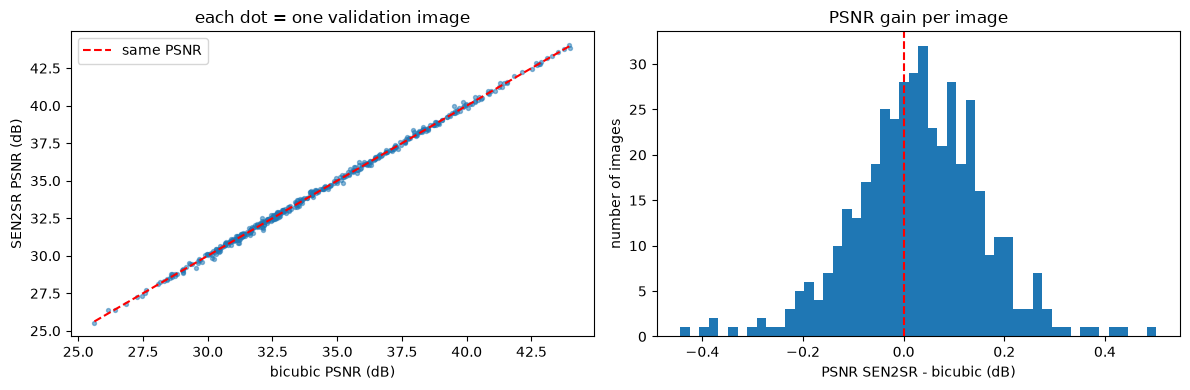

In [16]:
diff_psnr = sr_res["psnr"] - bic_res["psnr"]

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.scatter(bic_res["psnr"], sr_res["psnr"], s=8, alpha=0.5)
lims = [bic_res["psnr"].min(), bic_res["psnr"].max()]
plt.plot(lims, lims, "r--", label="same PSNR")
plt.xlabel("bicubic PSNR (dB)")
plt.ylabel("SEN2SR PSNR (dB)")
plt.legend()
plt.title("each dot = one validation image")

plt.subplot(1, 2, 2)
plt.hist(diff_psnr, bins=50)
plt.axvline(0, color="red", linestyle="--")
plt.xlabel("PSNR SEN2SR - bicubic (dB)")
plt.ylabel("number of images")
plt.title("PSNR gain per image")
plt.tight_layout()
plt.show()

PSNR per band - does SEN2SR help all bands equally?

In [17]:
band_rows = []
for i, row in val.iterrows():
    lr, hr = load_pair(row)
    bic, sr = crop(bicubic(lr, use_antialias)), crop(super_resolve(lr))
    h = crop(hr)
    for b, band in enumerate(band_names):
        band_rows.append({"band": band, "bicubic": psnr(bic[b], h[b]), "sen2sr": psnr(sr[b], h[b])})

band_df = pd.DataFrame(band_rows)
band_table = band_df.groupby("band")[["bicubic", "sen2sr"]].mean().loc[band_names]
band_table["gain"] = band_table["sen2sr"] - band_table["bicubic"]
band_table.round(3)

,bicubic,sen2sr,gain
band,,,
R,35.415001,35.453999,0.039
G,37.963001,37.993999,0.031
B,40.449001,40.493999,0.044
NIR,31.402000,31.421000,0.020


## 6. Looking at the images

Numbers are not everything. Let's look at three validation images: the one where SEN2SR gains the most PSNR, a typical one (median gain), and the one where it loses the most. We zoom into a 120 x 120 HR-pixel area (300 m) and also show the error |prediction - HR|.

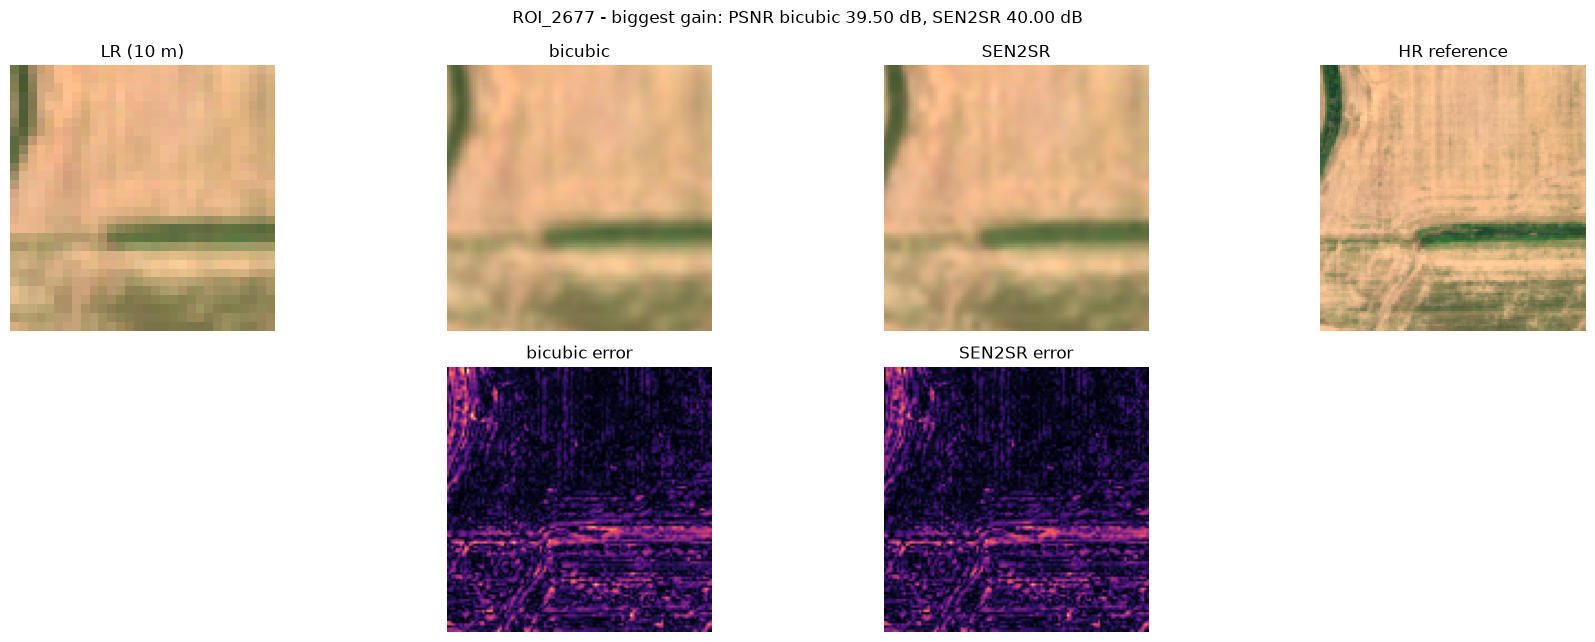

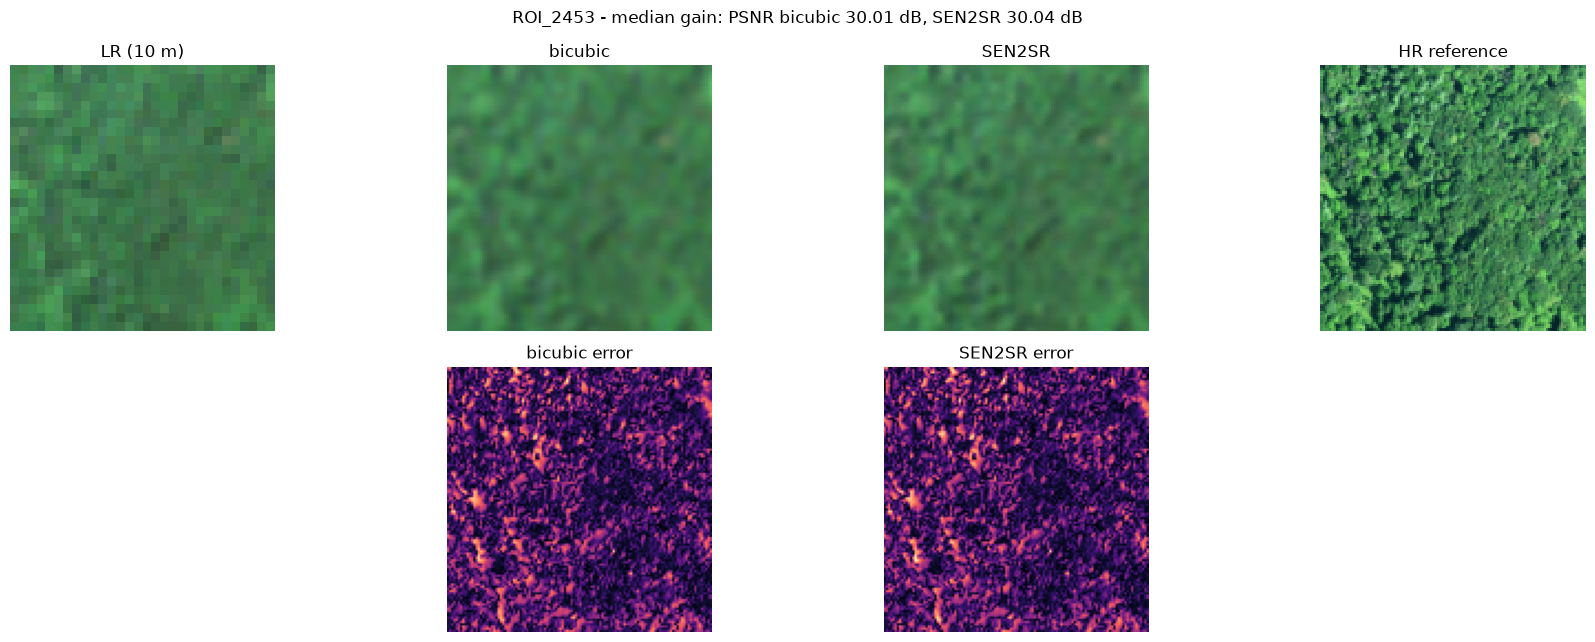

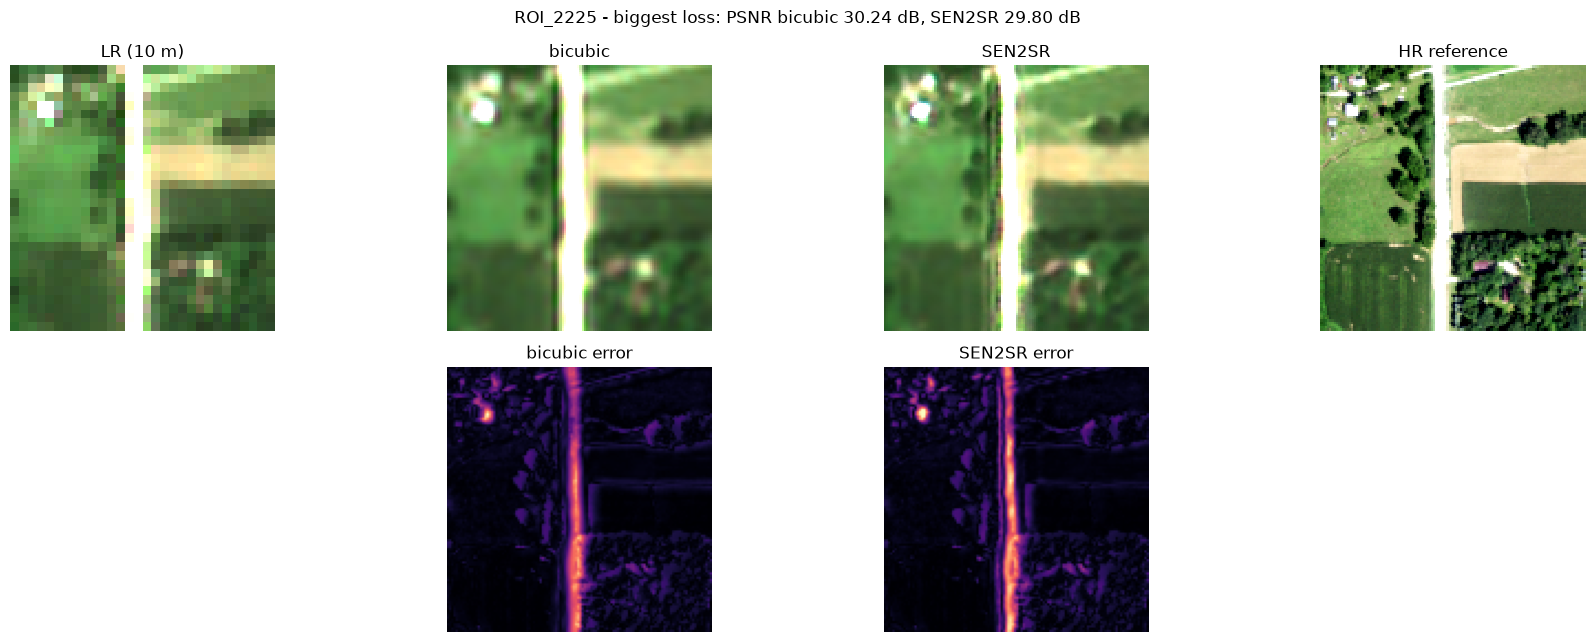

In [18]:
order = diff_psnr.sort_values()
examples = {"biggest gain": order.index[-1], "median gain": order.index[len(order) // 2], "biggest loss": order.index[0]}

def to_rgb(img, stretch):
    return np.clip(img[:3].transpose(1, 2, 0) / stretch, 0, 1)

for title, folder in examples.items():
    row = val[val["folder"] == folder].iloc[0]
    lr, hr = load_pair(row)
    bic, sr = bicubic(lr, use_antialias), super_resolve(lr)
    stretch = np.percentile(hr[:3], 99)
    y, x = 180, 180
    zoom = lambda img: img[:, y:y + 120, x:x + 120]
    zoom_lr = lr[:, y // 4:(y + 120) // 4, x // 4:(x + 120) // 4]

    plt.figure(figsize=(18, 6.5))
    plt.suptitle(f"{folder} - {title}: PSNR bicubic {bic_res.loc[folder, 'psnr']:.2f} dB, SEN2SR {sr_res.loc[folder, 'psnr']:.2f} dB")
    images = [("LR (10 m)", zoom_lr), ("bicubic", zoom(bic)), ("SEN2SR", zoom(sr)), ("HR reference", zoom(hr))]
    for k, (name, img) in enumerate(images):
        plt.subplot(2, 4, k + 1)
        plt.imshow(to_rgb(img, stretch), interpolation="nearest")
        plt.title(name)
        plt.axis("off")
    err_max = np.abs(zoom(bic) - zoom(hr))[:3].mean(0).max()
    for k, (name, img) in enumerate([("bicubic error", zoom(bic)), ("SEN2SR error", zoom(sr))]):
        plt.subplot(2, 4, k + 6)
        plt.imshow(np.abs(img - zoom(hr))[:3].mean(0), cmap="magma", vmin=0, vmax=err_max)
        plt.title(name)
        plt.axis("off")
    plt.tight_layout()
    plt.show()

What we see:
- In all three, SEN2SR is only **slightly** sharper than bicubic. Both are much blurrier than the HR reference. The error maps of bicubic and SEN2SR look almost the same: most error is on edges and fine texture that neither method recovers.
- **Biggest loss (ROI_2225):** the road in the LR is not exactly where the road is in the HR - the two images are slightly shifted. SEN2SR makes the road edge sharper, but in the wrong place, and adds a thin dark line next to it (ringing). A sharp edge in the wrong place is punished more than a blurry one, so bicubic wins here.

So PSNR can punish sharpening when the reference is not perfectly aligned. That's why we also look at SSIM, SAM and the pictures, not only PSNR.

## 7. Save the results

In [19]:
results.to_csv("phase2_val_results.csv", index=False)
print("saved phase2_val_results.csv", results.shape)

saved phase2_val_results.csv (866, 9)


## Quick checks

In [20]:
assert len(results) == 2 * len(val)
assert results[metrics].notna().all().all()
assert set(results["folder"]) <= set(val["folder"])                  # only validation images
assert not results["folder"].isin(index.loc[index["split"] == "test", "folder"]).any()   # test split untouched
assert (results["ssim"] <= 1).all() and (results["sam"] >= 0).all()
print("all checks passed")

all checks passed


## Summary

Validation split, 433 images (test split not used). Fixed data range 1.0, 8 px border removed.

| | bicubic | SEN2SR | SEN2SR better on |
|---|---|---|---|
| PSNR (dB) | 34.28 | 34.31 | 60% of images |
| SSIM | 0.845 | 0.849 | 74% |
| MAE | 0.0135 | 0.0134 | 69% |
| SAM (°) | 2.180 | 2.175 | 46% |
| LR consistency (dB) | 57.2 | 59.3 | 99.5% |
| time per image | 1.5 ms | ~21 ms | |

What this means:
- **SEN2SR is better than bicubic, but only a little.** PSNR +0.03 dB (95% CI +0.017 to +0.042), SSIM +0.004. The difference is real (the CI does not include 0) but small. On good-fit images the gain is a bit larger (+0.046 dB).
- **LR consistency is clearly better** (99.5% of images): the FFT hard constraint keeps the output faithful to what the satellite measured.
- **Spectrum (SAM):** almost no change; SEN2SR is better on fewer than half the images. It does not distort the colours, but it does not improve them either.
- All 4 bands gain about the same; NIR is the hardest band for both methods.
- The pictures show why the gain is small: SEN2SR adds only a little detail, and where LR and HR are slightly shifted, sharper edges are punished.

Possible reasons (to check in the next phases, not proven yet):
1. SEN2SR was trained on simulated Sentinel-2 images, not on real Sentinel-2 / NAIP pairs like ours → **LoRA fine-tuning (Phase 4)** on our training split might help.
2. The model adds little high-frequency detail → **Phase 3** looks at the frequency spectrum of the errors to see where they are.
3. Small LR-HR shifts in the dataset limit how much any sharp method can gain in PSNR.

These are the numbers every modification has to beat.